# NovaRetail+: ¿qué factores del comportamiento del cliente se asocian con el ingreso anual?

**Contexto.** NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios. Para el cierre de 2024, el equipo de **Crecimiento y Retención** necesita entender qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual que genera.

**Pregunta de negocio:** ¿qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?

> Este es un análisis **correlacional y exploratorio**. **Correlación ≠ causalidad:** los hallazgos describen asociaciones y señalan dónde probar con experimentos, no demuestran efectos.

**Datos:** 15.000 clientes de 2024 (`data/novaretail_comportamiento_clientes_2024.csv`). **Stack:** Python (pandas, NumPy, SciPy, seaborn, matplotlib) en Jupyter Notebook.

**Contenido:** 1. Carga y exploración · 2. Preparación de datos y supuestos · 3. Visualización de relaciones · 4. Coeficientes de correlación y evidencia numérica · 5. Interpretación para el negocio · 6. Recomendaciones y próximos pasos · 7. Limitaciones.

---

## 1. Cargar y explorar el dataset

En esta sección se valida que el dataset cargue correctamente, sus tipos de datos y los valores faltantes y rangos generales. Antes de correlacionar, primero se entiende el "terreno".

In [1]:
# Importar librerías

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import pointbiserialr, chi2_contingency, mannwhitneyu, kruskal

### 1.1 Carga del dataset

In [2]:
# Cargar el dataset y explorar datos

df = pd.read_csv('../data/novaretail_comportamiento_clientes_2024.csv')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.

In [3]:
# Mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


---

## 2. Preparar datos y documentar supuestos

### 2.1 Exploración inicial y limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` se encontraba como `float64` (por ejemplo, 44.0), a pesar de representar una cantidad entera de años. Por este motivo, se convirtió a `int64` para reflejar correctamente su naturaleza discreta.

**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Convertir edad a entero (todos los valores son años completos)
assert (df['edad'] == df['edad'].round()).all()
df['edad'] = df['edad'].astype(int)

df['edad'].dtype

dtype('int64')

### 2.2 Variables binarias

In [5]:
print("Valores únicos de miembro_premium:", df["miembro_premium"].unique())
print("Valores únicos de abandono:", df["abandono"].unique())

Valores únicos de miembro_premium: [0 1]
Valores únicos de abandono: [0 1]


#### Diagnóstico inicial de variables binarias

- `miembro_premium` — La variable contiene únicamente los valores 0 y 1,
  por lo que está correctamente codificada como variable binaria. El valor
  1 representa a los clientes con membresía premium y el valor 0 a los
  clientes sin membresía premium.

- `abandono` — La variable contiene únicamente los valores 0 y 1,
  por lo que está correctamente codificada como variable binaria. El valor
  1 representa a los clientes que abandonaron la plataforma y el valor 0
  a los clientes que permanecieron.

**Conclusión:** Ambas variables presentan una estructura binaria correcta
y no requieren transformación adicional.

### 2.3 Variables categóricas

In [6]:
# Verificar el número de valores únicos por variable categórica
print("tipo_dispositivo:", df["tipo_dispositivo"].nunique())
print("region:", df["region"].nunique())

tipo_dispositivo: 3
region: 4


In [7]:
# Explorar variables categóricas y cómo se distribuyen

print("Distribución de tipo_dispositivo:")
print(df["tipo_dispositivo"].value_counts())

print("\nDistribución de region:")
print(df["region"].value_counts())

Distribución de tipo_dispositivo:
tipo_dispositivo
móvil         9818
escritorio    3720
tablet        1462
Name: count, dtype: int64

Distribución de region:
region
norte    4395
oeste    3810
sur      3726
este     3069
Name: count, dtype: int64


#### Diagnóstico inicial de variables categóricas

#### Tipo de dispositivo

- `móvil` — Representa 9,818 clientes (65.5%) y es la categoría
  predominante. Aproximadamente dos de cada tres clientes utilizan este
  tipo de dispositivo.

- `escritorio` — Representa 3,720 clientes (24.8%). Es la segunda
  categoría con mayor participación, aunque se encuentra bastante por
  debajo de móvil.

- `tablet` — Representa 1,462 clientes (9.7%). Es la categoría con menor
  representación y concentra menos de una décima parte de los registros.

**Punto clave:** Existe un desbalance importante en `tipo_dispositivo`,
principalmente debido al predominio de móvil. Las comparaciones entre
dispositivos deben considerar que los grupos no tienen el mismo tamaño.

---

#### Región

- `norte` — Representa 4,395 clientes (29.3%) y es la región con mayor
  participación.

- `oeste` — Representa 3,810 clientes (25.4%) y ocupa el segundo lugar
  en cantidad de registros.

- `sur` — Representa 3,726 clientes (24.8%), con una participación muy
  cercana a la región oeste.

- `este` — Representa 3,069 clientes (20.5%) y es la región con menor
  representación.

**Punto clave:** La distribución de `region` es más equilibrada que la de
`tipo_dispositivo`. La diferencia entre la región con mayor y menor
representación es de 8.8 puntos porcentuales, por lo que no existe una
categoría regional que domine claramente el dataset.

---

#### Aspectos a tener en cuenta para el análisis

1. `tipo_dispositivo` presenta un desbalance considerable: móvil concentra
   el 65.5% de los clientes, mientras que tablet representa solo el 9.7%.

2. `region` presenta una distribución relativamente equilibrada, aunque
   norte tiene la mayor representación (29.3%) y este la menor (20.5%).

3. Las diferencias en el tamaño de los grupos deben considerarse al
   comparar el `ingreso_anual` entre categorías.

4. Una mayor cantidad de clientes en una categoría no significa
   necesariamente que esa categoría genere mayores ingresos por cliente.
   Será necesario analizar también métricas como el ingreso promedio o
   mediano por segmento.

5. Para estudiar asociaciones entre variables categóricas utilizaremos
   métodos apropiados, como V de Cramér, en lugar de interpretar
   directamente las frecuencias como relaciones.

6. Las diferencias observadas describen la composición de la muestra y no
   permiten establecer relaciones causales.

### 2.4 Validación de calidad de datos

Antes de asumir que los datos no tienen errores, se comprueban duplicados, valores faltantes y rangos válidos.

In [8]:
# Validación de calidad: duplicados, nulos y rangos
print("Identificadores duplicados:", df['id_cliente'].duplicated().sum())
print("Valores nulos en total:", df.isna().sum().sum())
print("Satisfacción fuera del rango 1-5:", ((df['satisfaccion'] < 1) | (df['satisfaccion'] > 5)).sum())

columnas_no_negativas = ['nivel_ingreso', 'visitas_mes', 'compras_mes',
                         'gasto_publicidad_dirigida', 'ingreso_anual']
print("Valores negativos:", (df[columnas_no_negativas] < 0).sum().sum())
print("Rango de edad:", df['edad'].min(), "a", df['edad'].max(), "años")

Identificadores duplicados: 0
Valores nulos en total: 0
Satisfacción fuera del rango 1-5: 0
Valores negativos: 0
Rango de edad: 18 a 75 años


### 2.5 Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible** (15.000 clientes).
- Los datos no presentan errores: no hay duplicados, nulos, valores negativos ni satisfacciones fuera de 1 a 5, y las variables están correctamente tipificadas (sección 2.4).
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **V de Cramér** se usa para asociaciones entre variables categóricas.

**Supuesto central:** este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

---

## 3. Visualización de relaciones

### 3.1 Heatmap

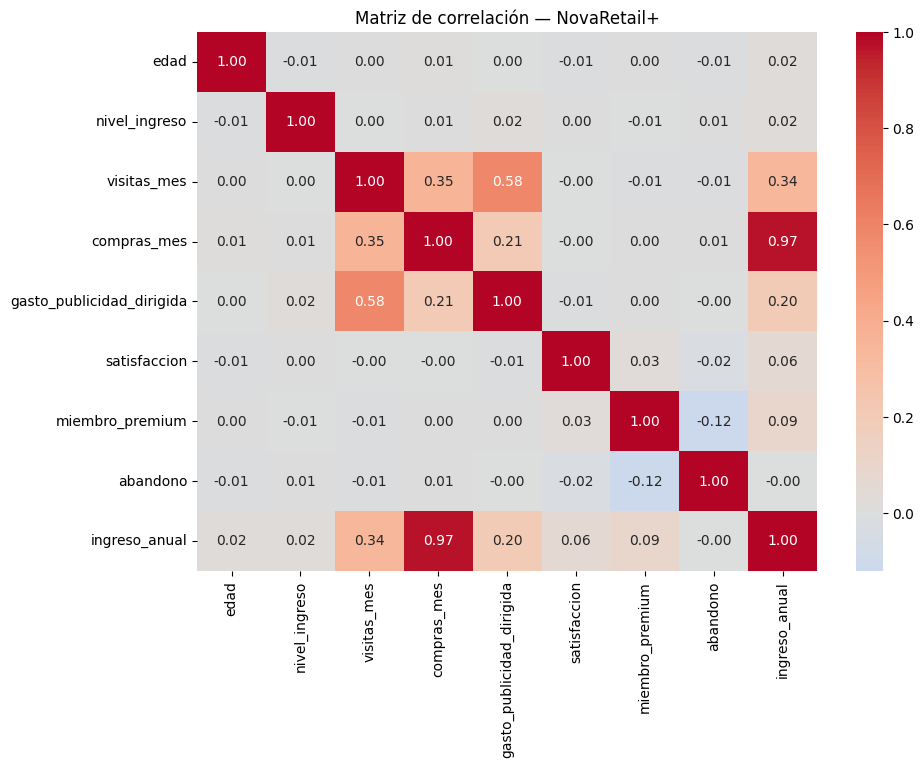

In [9]:
# Visualizar la matriz de correlación para identificar relaciones

columnas_numericas = [
    "edad",
    "nivel_ingreso",
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "satisfaccion",
    "miembro_premium",
    "abandono",
    "ingreso_anual"
]

corr = df[columnas_numericas].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Matriz de correlación — NovaRetail+")
plt.show()

## Observaciones iniciales (Heatmap)

### `compras_mes` vs `ingreso_anual`

- **Correlación aproximada:** 0.97
- **Dirección:** **Positiva**.
- **Fuerza de la asociación:** **Muy fuerte** — es, por amplio margen, la variable con mayor asociación con `ingreso_anual` en todo el heatmap.
- **Observación:** Los clientes que compran con más frecuencia en el mes tienden a generar consistentemente más ingreso anual.
- **Por qué podría ser relevante:** Sugiere que la frecuencia de compra es el factor más asociado al valor económico del cliente.
- **Qué NO podemos concluir:** No podemos afirmar que comprar más "genera" o "causa" mayor ingreso — dado lo cercano que está a 1.0, se revisó si ambas variables están relacionadas por definición (secciones 3.3 y 4.4): así es.

---

### `visitas_mes` vs `ingreso_anual`

- **Correlación aproximada:** 0.34
- **Dirección:** **Positiva**.
- **Fuerza de la asociación:** **Moderada**.
- **Observación:** Segunda variable más asociada con `ingreso_anual`, aunque muy por debajo de `compras_mes`.
- **Por qué podría ser relevante:** Sugiere que la frecuencia de visita al sitio/app podría estar relacionada con el comportamiento de gasto del cliente.
- **Qué NO podemos concluir:** No sabemos si más visitas llevan a más compras, o si los clientes que ya compran más simplemente visitan más.

---

### `gasto_publicidad_dirigida` vs `ingreso_anual`

- **Correlación aproximada:** 0.20
- **Dirección:** **Positiva**.
- **Fuerza de la asociación:** **Débil a moderada**.
- **Observación:** Asociación positiva pero modesta con `ingreso_anual`.
- **Por qué podría ser relevante:** Podría indicar alguna relación entre inversión en publicidad dirigida y el valor del cliente, aunque es una señal débil por sí sola.
- **Qué NO podemos concluir:** No podemos afirmar que la publicidad "produce" mayor ingreso; la dirección de la relación no está establecida.

---

### `miembro_premium` vs `ingreso_anual`

- **Correlación aproximada:** 0.09
- **Dirección:** **Positiva**.
- **Fuerza de la asociación:** **Débil**.

### 3.2 Scatterplots para pares clave

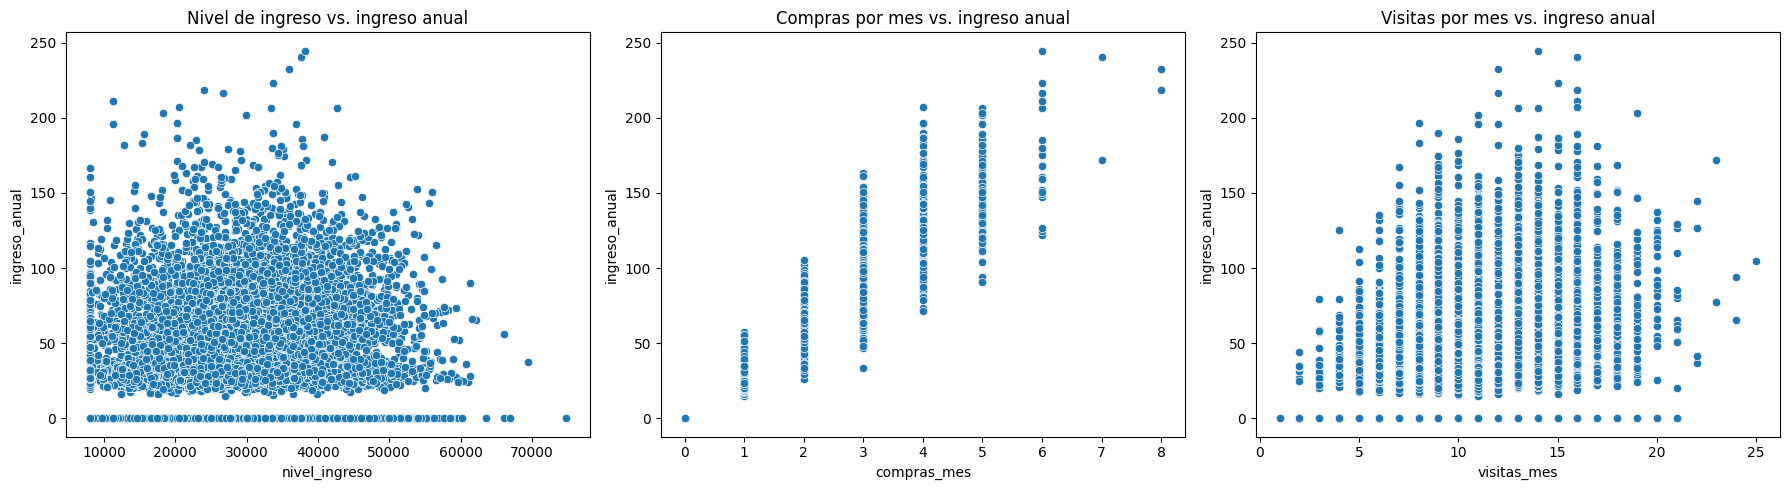

In [10]:
# Scatterplots de las relaciones más relevantes con ingreso_anual

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=df,
    x="nivel_ingreso",
    y="ingreso_anual",
    ax=axes[0]
)
axes[0].set_title("Nivel de ingreso vs. ingreso anual")

sns.scatterplot(
    data=df,
    x="compras_mes",
    y="ingreso_anual",
    ax=axes[1]
)
axes[1].set_title("Compras por mes vs. ingreso anual")

sns.scatterplot(
    data=df,
    x="visitas_mes",
    y="ingreso_anual",
    ax=axes[2]
)
axes[2].set_title("Visitas por mes vs. ingreso anual")

plt.tight_layout()
plt.show()

## Observaciones iniciales (Scatterplot)

### `nivel_ingreso` vs `ingreso_anual`

- **Dirección:** sin relación visual clara.
- **Dispersión:** **alta** — los puntos se distribuyen de forma uniforme en todo el rango de `nivel_ingreso`, sin agruparse en torno a una tendencia.
- **Forma:** sin patrón visual claro.
- **Outliers:** no se observan outliers claros.
- **Clusters:** se observa una línea densa de puntos en `ingreso_anual = 0` que atraviesa todo el rango de `nivel_ingreso`, lo que sugiere un grupo diferenciado de clientes con ingreso anual nulo (se analiza en la sección 3.3).
- **Relevancia para `ingreso_anual`:** la nube de puntos no muestra tendencia ascendente ni descendente; visualmente `nivel_ingreso` no parece estar asociado con `ingreso_anual`.

---

### `compras_mes` vs `ingreso_anual`

- **Dirección:** **positiva**.
- **Dispersión:** **baja a media** — dentro de cada valor de `compras_mes` los puntos se agrupan en un rango acotado, con algo más de dispersión en valores altos (6-8 compras).
- **Forma:** **aproximadamente lineal** — progresión ascendente ordenada conforme aumenta `compras_mes`.
- **Outliers:** no se observan outliers claros.
- **Clusters:** los puntos se agrupan en columnas verticales discretas (0, 1, 2, 3...), consistente con que `compras_mes` es una variable de conteo entero.
- **Relevancia para `ingreso_anual`:** es la relación visualmente **más fuerte** de las tres.

---

### `visitas_mes` vs `ingreso_anual`

- **Dirección:** **positiva**, aunque menos definida que en `compras_mes`.
- **Dispersión:** **alta** — para un mismo número de visitas, el `ingreso_anual` varía ampliamente (por ejemplo, con 12 a 16 visitas los valores van desde 0 hasta más de 200).
- **Forma:** **creciente y aproximadamente lineal en promedio**: el ingreso medio sube de forma sostenida a medida que aumentan las visitas (de unos 18 con 6 visitas o menos a unos 66 con más de 16), sin una meseta. La dispersión individual es lo que hace que la nube se vea difusa (ver sección 4.5).
- **Outliers:** no se observan outliers claros y aislados.
- **Clusters:** no se observan grupos diferenciados claros, salvo la concentración de puntos en `ingreso_anual = 0` vista en los otros gráficos.
- **Relevancia para `ingreso_anual`:** relación **positiva pero débil a moderada**; las visitas por sí solas explican mucho menos que las compras.

---

### Conclusión visual general

De los tres pares analizados, **`compras_mes` vs `ingreso_anual`** muestra la relación más **fuerte**, clara y ordenada, con tendencia positiva y forma aproximadamente lineal. **`visitas_mes`** muestra una relación **positiva pero débil a moderada**, con dispersión alta. **`nivel_ingreso`** no presenta ningún patrón visual claro con `ingreso_anual`. El elemento repetido en los tres gráficos es la banda de puntos en `ingreso_anual = 0`, que se investiga a continuación.

### 3.3 ¿Qué hay detrás de la banda de `ingreso_anual = 0`?

Los tres scatterplots muestran una línea de clientes con ingreso nulo. Se comprueba si coincide con los clientes que no compran y cómo se relaciona el ingreso con el número de compras.

In [11]:
# La banda de ingreso_anual = 0: ¿son los clientes sin compras?
sin_ingreso = df['ingreso_anual'] == 0
sin_compras = df['compras_mes'] == 0

print(pd.crosstab(sin_ingreso, sin_compras, rownames=['ingreso_anual = 0'], colnames=['compras_mes = 0']))
print(f"\nClientes sin compras: {sin_compras.sum()} ({sin_compras.mean():.1%})")

# Ingreso por compra entre quienes sí compran
compradores = df[df['compras_mes'] > 0].copy()
compradores['ticket'] = compradores['ingreso_anual'] / compradores['compras_mes']
print("\nIngreso por compra (ingreso_anual / compras_mes) entre compradores:")
print(compradores['ticket'].describe().round(2))

compras_mes = 0    False  True 
ingreso_anual = 0              
False              10433      0
True                   0   4567

Clientes sin compras: 4567 (30.4%)

Ingreso por compra (ingreso_anual / compras_mes) entre compradores:
count    10433.00
mean        30.38
std          5.34
min         11.20
25%         26.78
50%         30.07
75%         33.47
max         57.29
Name: ticket, dtype: float64


In [12]:
# Ingreso anual promedio según el número de compras
df.groupby('compras_mes')['ingreso_anual'].agg(clientes='count', ingreso_medio='mean', desviacion='std').round(1)

,clientes,ingreso_medio,desviacion
compras_mes,,,
0,4567,0.0,0.0
1,5306,30.4,5.3
2,3236,60.7,10.8
3,1390,90.9,16.4
4,386,121.3,21.5
5,91,147.4,23.7
6,20,172.6,34.0
7,2,206.4,48.4
8,2,225.7,10.0


**Hallazgo:** la banda de `ingreso_anual = 0` corresponde **exactamente** a los clientes con `compras_mes = 0`: los 4.567 clientes sin compras (30,4%) tienen ingreso nulo y ningún cliente con compras tiene ingreso nulo. Entre quienes compran, el ingreso por compra es casi constante (media de $30,38 y desviación de $5,34), y el ingreso medio crece prácticamente en proporción al número de compras (30,4 con 1 compra, 60,7 con 2, 90,9 con 3).

**Consecuencia:** la correlación de 0,97 entre `compras_mes` e `ingreso_anual` es en gran parte una relación **por construcción** (ingreso ≈ compras × ticket), no un hallazgo de comportamiento. La pregunta útil para el negocio pasa a ser **qué se asocia con que el cliente compre más y con un ticket mayor**, que se analiza en las secciones 4.4 y 4.5.

---

## 4. Coeficientes de correlación y evidencia numérica

### 4.1 Pearson y Spearman

In [13]:
# Calcular correlaciones Pearson y Spearman con ingreso_anual

variables_relevantes = [
    "nivel_ingreso",
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "satisfaccion",
    "edad"
]

for variable in variables_relevantes:
    pearson = df["ingreso_anual"].corr(df[variable], method="pearson")
    spearman = df["ingreso_anual"].corr(df[variable], method="spearman")
    
    print(f"\n{variable} vs ingreso_anual")
    print(f"Pearson:  {pearson:.3f}")
    print(f"Spearman: {spearman:.3f}")


nivel_ingreso vs ingreso_anual
Pearson:  0.017
Spearman: 0.025

visitas_mes vs ingreso_anual
Pearson:  0.337
Spearman: 0.321

compras_mes vs ingreso_anual
Pearson:  0.967
Spearman: 0.967

gasto_publicidad_dirigida vs ingreso_anual
Pearson:  0.197
Spearman: 0.185

satisfaccion vs ingreso_anual
Pearson:  0.056
Spearman: 0.061

edad vs ingreso_anual
Pearson:  0.017
Spearman: 0.016


### Observaciones de correlación

**`compras_mes` vs `ingreso_anual`**
- **Dirección:** Positiva.
- **Pearson:** 0.967
- **Spearman:** 0.967
- **Magnitud:** **Muy fuerte**.
- **Interpretación cuantitativa:** Ambos coeficientes son prácticamente idénticos y muy cercanos a 1, lo que indica una relación lineal y monotónica extremadamente consistente entre `compras_mes` e `ingreso_anual`.
- **Interpretación cualitativa:** Los clientes que realizan más compras al mes tienden a acompañarse de un ingreso anual considerablemente mayor. Es, con amplio margen, la asociación más fuerte del análisis.
- **Posible colinealidad:** No aplica directamente (se compara con la variable objetivo, no entre predictoras).
- **Qué revisar:** dada la cercanía a 1.0, se verificó si `ingreso_anual` depende de `compras_mes` por construcción (secciones 3.3 y 4.4): el ingreso es 0 exactamente cuando no hay compras y, entre compradores, equivale a unos $30,38 por compra. Es una relación casi matemática, no un hallazgo de comportamiento nuevo.

---

**`visitas_mes` vs `ingreso_anual`**
- **Dirección:** Positiva.
- **Pearson:** 0.337
- **Spearman:** 0.321
- **Magnitud:** **Moderada**.
- **Interpretación cuantitativa:** Pearson y Spearman son similares, lo que sugiere que la relación lineal y la monotónica presentan un comportamiento parecido, sin evidencia fuerte de no linealidad.
- **Interpretación cualitativa:** Los clientes con más visitas mensuales tienden a acompañarse de un ingreso anual algo mayor, aunque de forma bastante menos marcada que con `compras_mes`.
- **Posible colinealidad:** No aplica directamente (se compara con la variable objetivo, no entre predictoras).
- **Qué revisar:** se revisó en el scatterplot (sección 3.2) y por tramos: la relación se mantiene creciente en todo el rango de visitas.

---

**`gasto_publicidad_dirigida` vs `ingreso_anual`**
- **Dirección:** Positiva.
- **Pearson:** 0.197
- **Spearman:** 0.185
- **Magnitud:** **Débil**.
- **Interpretación cuantitativa:** Ambos coeficientes son similares y bajos, indicando consistencia entre el comportamiento lineal y monotónico, pero con una asociación limitada.
- **Interpretación cualitativa:** El gasto en publicidad dirigida se asocia levemente con el ingreso anual, aunque la relación es modesta por sí sola.
- **Posible colinealidad:** Presenta una correlación más alta con `visitas_mes` (0.58, según el heatmap) que con `ingreso_anual` — esto podría indicar cierta redundancia de información entre `gasto_publicidad_dirigida` y `visitas_mes` como posibles predictoras.
- **Qué revisar:** se comprobó si el efecto de la publicidad se observa mejor de forma indirecta (a través de `visitas_mes`): al controlar las visitas, la correlación parcial de la publicidad con las compras cae a 0,004 (sección 4.5).

---

**`satisfaccion` vs `ingreso_anual`**
- **Dirección:** Positiva.
- **Pearson:** 0.056
- **Spearman:** 0.061
- **Magnitud:** **Muy débil**.
- **Interpretación cuantitativa:** Ambos coeficientes son bajos y similares entre sí, sin indicios de no linealidad relevante.
- **Interpretación cualitativa:** No se observa una asociación relevante entre la satisfacción del cliente y el ingreso anual generado; el efecto visible es mínimo.
- **Posible colinealidad:** No se observan señales relevantes con otras variables predictoras.
- **Qué revisar:** Esta correlación es demasiado baja para considerarse un hallazgo por sí sola; no amerita mayor profundización salvo como parte de un análisis conjunto.

---

**`nivel_ingreso` vs `ingreso_anual`**
- **Dirección:** Prácticamente nula.
- **Pearson:** 0.017
- **Spearman:** 0.025
- **Magnitud:** **Muy débil**.
- **Interpretación cuantitativa:** Ambos coeficientes son cercanos a cero y consistentes entre sí, sin evidencia de relación lineal ni monotónica relevante.
- **Interpretación cualitativa:** El nivel de ingreso personal del cliente no muestra una asociación relevante con el ingreso anual que genera para la plataforma.
- **Posible colinealidad:** No se observan señales relevantes con otras variables predictoras.
- **Qué revisar:** No amerita revisión adicional; la correlación es demasiado baja para constituir un hallazgo.

---

**`edad` vs `ingreso_anual`**
- **Dirección:** Prácticamente nula.
- **Pearson:** 0.017
- **Spearman:** 0.016
- **Magnitud:** **Muy débil**.
- **Interpretación cuantitativa:** Ambos coeficientes son casi idénticos y cercanos a cero, mostrando consistencia entre ambos métodos, pero sin relación relevante.
- **Interpretación cualitativa:** La edad del cliente no se asocia de forma relevante con el ingreso anual generado.
- **Posible colinealidad:** No se observan señales relevantes con otras variables predictoras.
- **Qué revisar:** No amerita revisión adicional.

---

### Conclusión general

Las asociaciones más relevantes con `ingreso_anual` son, en orden de fuerza: **`compras_mes`** (muy fuerte, 0.967), **`visitas_mes`** (moderada, ~0.33) y **`gasto_publicidad_dirigida`** (débil, ~0.19). Las variables **`satisfaccion`**, **`nivel_ingreso`** y **`edad`** presentan correlaciones prácticamente nulas y no constituyen hallazgos relevantes por sí solas.

En cuanto a colinealidad, se identifica una señal a vigilar entre **`gasto_publicidad_dirigida`** y **`visitas_mes`** (0.58 según el heatmap), lo que sugiere posible información redundante entre ambas como variables predictoras del comportamiento del cliente.

Las relaciones que deberían pasar a la siguiente etapa de análisis (visualización y segmentación) son **`compras_mes`**, **`visitas_mes`** y, en menor medida, **`gasto_publicidad_dirigida`**, dada su asociación relativa con `ingreso_anual`.

Con base únicamente en estos coeficientes de correlación, **no puede establecerse** que alguna de estas variables cause o determine el ingreso anual del cliente, ni puede descartarse que las variables con correlación baja carezcan de relevancia bajo otras formas de análisis (por ejemplo, relaciones no lineales o efectos que solo se observan al segmentar por grupos).

### 4.2 Punto biserial

In [14]:
# Calcular correlación punto-biserial
variables_binarias = ["miembro_premium", "abandono"]

for variable in variables_binarias:
    coef, p_value = pointbiserialr(
        df[variable],
        df["ingreso_anual"]
    )

    print(f"\n{variable} vs ingreso_anual")
    print(f"Punto-biserial: {coef:.3f}")
    print(f"P-value: {p_value:.4f}")


miembro_premium vs ingreso_anual
Punto-biserial: 0.093
P-value: 0.0000

abandono vs ingreso_anual
Punto-biserial: -0.003
P-value: 0.7295


### Observaciones punto-biserial

**`miembro_premium` vs `ingreso_anual`**
- **Codificación:** 0 = cliente sin membresía premium, 1 = cliente con membresía premium
- **Coeficiente punto-biserial:** 0.093 (p-value: 0.0000)
- **Dirección:** Positiva.
- **Magnitud:** **Débil**.
- **Interpretación cuantitativa:** El coeficiente es positivo y estadísticamente significativo (p < 0.05), lo que indica que la asociación observada es poco probable que se deba al azar, aunque su magnitud sigue siendo baja.
- **Interpretación cualitativa:** Los clientes codificados como 1 (con membresía premium) tienden a presentar valores de `ingreso_anual` ligeramente mayores que los clientes sin membresía.
- **Relación con `ingreso_anual`:** El grupo de miembros premium se asocia con ingresos relativamente mayores, aunque la diferencia parece ser pequeña en términos de magnitud del coeficiente.
- **Qué muestran los datos:** Una asociación positiva y estadísticamente significativa, pero de magnitud débil, entre tener membresía premium y el ingreso anual generado.
- **Qué NO podemos afirmar:** No podemos afirmar que tener membresía premium "genera" o "provoca" un mayor ingreso anual, ni que la significancia estadística implique relevancia práctica importante dado lo bajo del coeficiente.
- **Qué revisar:** se comparan las medias y medianas de `ingreso_anual` entre ambos grupos a continuación, para dimensionar la diferencia real más allá del coeficiente.

---

**`abandono` vs `ingreso_anual`**
- **Codificación:** 0 = cliente que permaneció en la plataforma, 1 = cliente que abandonó la plataforma
- **Coeficiente punto-biserial:** -0.003 (p-value: 0.7295)
- **Dirección:** Prácticamente nula (leve tendencia negativa, no significativa).
- **Magnitud:** **Muy débil**.
- **Interpretación cuantitativa:** El coeficiente es cercano a cero y el p-value (0.7295) es muy superior a 0.05, lo que indica que esta asociación no es estadísticamente significativa y podría deberse simplemente al azar.
- **Interpretación cualitativa:** No se observa una diferencia relevante en `ingreso_anual` entre clientes que abandonaron la plataforma y los que permanecieron.
- **Relación con `ingreso_anual`:** No se identifica una asociación relevante entre el abandono del cliente y su ingreso anual generado.
- **Qué muestran los datos:** Una asociación prácticamente nula y no significativa entre `abandono` e `ingreso_anual`.
- **Qué NO podemos afirmar:** No podemos afirmar que el abandono esté relacionado con el ingreso anual, ni tampoco que no exista ninguna relación bajo otras formas de análisis (por ejemplo, segmentando por otras variables).
- **Qué revisar:** dado que la asociación no es significativa, no amerita mayor profundización como hallazgo aislado; se revisa en conjunto con `miembro_premium` en la sección 4.3, dada la correlación negativa (-0,12) observada entre ambas variables en el heatmap.

---

### Conclusión general

De las dos variables binarias analizadas, **`miembro_premium`** presenta la asociación más relevante con `ingreso_anual`: positiva, débil pero estadísticamente significativa (p < 0.05), donde el grupo con membresía premium (codificado como 1) tiende a presentar ingresos anuales ligeramente mayores. En contraste, **`abandono`** muestra una asociación prácticamente nula y no significativa (p = 0.7295), por lo que no se identifica una diferencia relevante en el ingreso anual entre clientes que abandonaron la plataforma y los que permanecieron.

Estas relaciones deberían investigarse con estadísticas descriptivas (medias, medianas) y visualizaciones como boxplots, para dimensionar mejor las diferencias entre grupos más allá del coeficiente. Con base únicamente en el análisis punto-biserial, **no puede establecerse** que la membresía premium cause un mayor ingreso, ni que el abandono esté exento de relación con el comportamiento económico del cliente bajo otras formas de análisis.

                 clientes  media  mediana
miembro_premium                          
0                   12911  35.30    29.95
1                    2089  44.58    37.70

Mann-Whitney (premium vs no premium): p = 2.238394886839591e-29


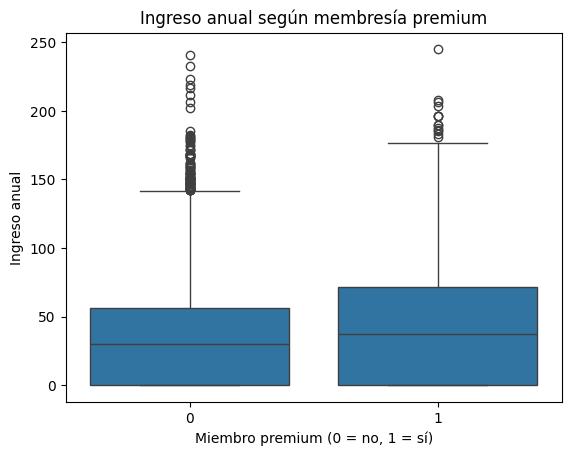

In [15]:
# Comparación de ingreso_anual entre clientes premium y no premium
print(df.groupby('miembro_premium')['ingreso_anual'].agg(clientes='count', media='mean', mediana='median').round(2))

premium = df.loc[df['miembro_premium'] == 1, 'ingreso_anual']
no_premium = df.loc[df['miembro_premium'] == 0, 'ingreso_anual']
print("\nMann-Whitney (premium vs no premium): p =", mannwhitneyu(premium, no_premium).pvalue)

sns.boxplot(data=df, x='miembro_premium', y='ingreso_anual')
plt.title('Ingreso anual según membresía premium')
plt.xlabel('Miembro premium (0 = no, 1 = sí)')
plt.ylabel('Ingreso anual')
plt.show()

Los clientes premium generan un ingreso anual medio de $44,58 frente a $35,30 de los no premium (+26%), y una mediana de $37,70 frente a $29,95. La diferencia es estadísticamente significativa (Mann-Whitney, p < 0,001) y sustancial en términos prácticos, aunque el coeficiente punto biserial (0,093) parezca pequeño: gran parte del ingreso depende de cuántas compras hace cada cliente, y eso es igual en ambos grupos (sección 4.5).

### 4.3 V de Cramér

Se calcula V de Cramér (con su prueba chi-cuadrado) para el par original, `tipo_dispositivo` vs `region`, y para los pares con `abandono`: `tipo_dispositivo`, `region` y `miembro_premium`.

In [16]:
# Función para calcular V de Cramér y su p-valor
def cramer_v(df, col1, col2):
    # Crear tabla de contingencia
    tabla = pd.crosstab(df[col1], df[col2])

    # Calcular chi-cuadrado
    chi2, p_value, dof, expected = chi2_contingency(tabla)

    # Número total de observaciones
    n = tabla.values.sum()

    # Calcular V de Cramér
    v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

    return v, p_value

In [17]:
# Aplicar V de Cramér en los pares relevantes
pares = [
    ("tipo_dispositivo", "region"),
    ("abandono", "tipo_dispositivo"),
    ("abandono", "region"),
    ("abandono", "miembro_premium"),
]

resultados_cramer = []
for col1, col2 in pares:
    v, p = cramer_v(df, col1, col2)
    resultados_cramer.append({"variable 1": col1, "variable 2": col2, "V de Cramér": round(v, 3), "p-valor": round(p, 4)})

pd.DataFrame(resultados_cramer)

,variable 1,variable 2,V de Cramér,p-valor
0,tipo_dispositivo,region,0.012,0.5965
1,abandono,tipo_dispositivo,0.007,0.6746
2,abandono,region,0.015,0.3117
3,abandono,miembro_premium,0.120,0.0000


In [18]:
# Tasa de abandono (%) por grupo
for col in ['miembro_premium', 'tipo_dispositivo', 'region']:
    print((df.groupby(col)['abandono'].mean() * 100).round(1).to_dict())
print("Abandono global:", round(df['abandono'].mean() * 100, 1), "%")

{0: 16.8, 1: 4.4}
{'escritorio': 15.3, 'móvil': 14.9, 'tablet': 15.6}
{'este': 14.7, 'norte': 14.4, 'oeste': 15.7, 'sur': 15.5}
Abandono global: 15.1 %


#### Observaciones V de Cramér

| Par de variables | V de Cramér | p-valor | Lectura |
|---|---|---|---|
| `tipo_dispositivo` vs `region` | 0,012 | 0,597 | Asociación nula |
| `abandono` vs `tipo_dispositivo` | 0,007 | 0,675 | Asociación nula |
| `abandono` vs `region` | 0,015 | 0,312 | Asociación nula |
| `abandono` vs `miembro_premium` | 0,120 | < 0,001 | Asociación débil pero significativa |

- **Dispositivo y región son independientes entre sí** (V = 0,012): ninguna región utiliza preferentemente un tipo de dispositivo.
- **El abandono no depende del dispositivo ni de la región** (V = 0,007 y 0,015): las tasas de abandono son prácticamente iguales entre dispositivos (14,9% a 15,6%) y entre regiones (14,4% a 15,7%).
- **El abandono sí se asocia con la membresía premium** (V = 0,120): los clientes premium abandonan el 4,4% frente al 16,8% de los no premium, es decir, casi cuatro veces menos. Es una asociación débil en magnitud, pero consistente y significativa con 15.000 clientes.
- **Qué no podemos afirmar:** que la membresía premium *cause* menor abandono. Los clientes que eligen ser premium podrían ser distintos de los demás desde el inicio (autoselección).

#### Ingreso por dispositivo y región

Faltaba comprobar directamente si el dispositivo o la región se relacionan con el ingreso (no solo con el abandono).

In [19]:
# Ingreso anual por dispositivo y por región
for col in ['tipo_dispositivo', 'region']:
    print(df.groupby(col)['ingreso_anual'].agg(clientes='count', media='mean', mediana='median').round(2))
    p = kruskal(*[g['ingreso_anual'] for _, g in df.groupby(col)]).pvalue
    print(f"Kruskal-Wallis: p = {p:.3f}\n")

                  clientes  media  mediana
tipo_dispositivo                          
escritorio            3720  36.42    30.44
móvil                 9818  36.59    30.69
tablet                1462  37.07    31.34
Kruskal-Wallis: p = 0.499

        clientes  media  mediana
region                          
este        3069  36.89    30.78
norte       4395  36.71    30.72
oeste       3810  35.72    30.36
sur         3726  37.10    30.94
Kruskal-Wallis: p = 0.448



El ingreso medio es prácticamente igual entre dispositivos ($36,42 a $37,07; Kruskal-Wallis p = 0,499) y entre regiones ($35,72 a $37,10; p = 0,448). **Ni el dispositivo ni la región distinguen a los clientes por el ingreso que generan.**

### 4.4 Ingreso por compra (ticket implícito)

Como el ingreso depende casi mecánicamente de las compras (sección 3.3), se analiza el **ingreso por compra** (`ingreso_anual ÷ compras_mes`) entre los clientes que sí compran, para ver qué se asocia con que cada compra valga más.

In [20]:
# Ticket por compra según membresía premium y satisfacción (solo compradores)
print(compradores.groupby('miembro_premium')['ticket'].agg(clientes='count', media='mean', mediana='median').round(2))

compradores['tramo_satisfaccion'] = pd.cut(compradores['satisfaccion'], [0.99, 2, 3, 4, 5.01],
                                           labels=['1-2', '2-3', '3-4', '4-5'], right=False)
print()
print(compradores.groupby('tramo_satisfaccion', observed=True)['ticket'].agg(clientes='count', media='mean').round(2))

                 clientes  media  mediana
miembro_premium                          
0                    8967  29.35    29.37
1                    1466  36.67    36.53

                    clientes  media
tramo_satisfaccion                 
1-2                       90  25.29
2-3                     1693  28.06
3-4                     5414  30.02
4-5                     3236  32.33


Entre los clientes que compran, **los premium gastan $36,67 por compra frente a $29,35 de los no premium (+25%)**. El ticket también aumenta con la satisfacción: de $28,06 (satisfacción de 2 a 3) a $32,33 (4 a 5). El tramo de satisfacción de 1 a 2 tiene solo 90 clientes y se interpreta con cautela.

### 4.5 Qué se asocia con la frecuencia de compra, el ticket y el abandono

Para pasar de "qué se asocia con el ingreso" a "qué se puede mover", se comparan los mismos seis factores contra tres resultados: la **frecuencia de compra** (`compras_mes`, todos los clientes), el **ticket por compra** (compradores) y el **abandono** (todos los clientes).

In [21]:
# Correlación de cada factor con frecuencia de compra, ticket por compra y abandono
impulsores = ['visitas_mes', 'gasto_publicidad_dirigida', 'miembro_premium',
              'satisfaccion', 'nivel_ingreso', 'edad']

matriz_impulsores = pd.DataFrame({
    'Frecuencia de compra': df[impulsores].corrwith(df['compras_mes']),
    'Ticket por compra': compradores[impulsores].corrwith(compradores['ticket']),
    'Abandono': df[impulsores].corrwith(df['abandono']),
}).round(3)

matriz_impulsores

,Frecuencia de compra,Ticket por compra,Abandono
visitas_mes,0.354,-0.019,-0.009
gasto_publicidad_dirigida,0.208,-0.012,-0.005
miembro_premium,0.003,0.477,-0.120
satisfaccion,-0.004,0.317,-0.024
nivel_ingreso,0.007,0.069,0.006
edad,0.015,0.009,-0.012


In [22]:
# Correlación parcial: ¿la publicidad se asocia con las compras más allá de las visitas?
def residuos(y, X):
    X1 = np.column_stack([np.ones(len(X)), X])
    beta = np.linalg.lstsq(X1, y, rcond=None)[0]
    return y - X1 @ beta

def corr_parcial(a, b, control):
    ra = residuos(df[a].astype(float).values, df[control].values)
    rb = residuos(df[b].astype(float).values, df[control].values)
    return np.corrcoef(ra, rb)[0, 1]

print(f"compras vs. publicidad (bruta):                  {df['compras_mes'].corr(df['gasto_publicidad_dirigida']):.3f}")
print(f"compras vs. publicidad (controlando visitas):    {corr_parcial('compras_mes', 'gasto_publicidad_dirigida', ['visitas_mes']):.3f}")
print(f"compras vs. visitas (bruta):                     {df['compras_mes'].corr(df['visitas_mes']):.3f}")
print(f"compras vs. visitas (controlando publicidad):    {corr_parcial('compras_mes', 'visitas_mes', ['gasto_publicidad_dirigida']):.3f}")
print(f"visitas vs. publicidad:                          {df['visitas_mes'].corr(df['gasto_publicidad_dirigida']):.3f}")

compras vs. publicidad (bruta):                  0.208
compras vs. publicidad (controlando visitas):    0.004
compras vs. visitas (bruta):                     0.354
compras vs. visitas (controlando publicidad):    0.293
visitas vs. publicidad:                          0.579


**Lectura de la matriz** (correlaciones de Pearson):
- **Frecuencia de compra:** se asocia con `visitas_mes` (0,354) y, en menor medida, con `gasto_publicidad_dirigida` (0,208). La membresía premium, la satisfacción, el nivel de ingreso y la edad no muestran relación (|r| < 0,02).
- **Ticket por compra:** se asocia con `miembro_premium` (0,477) y con `satisfaccion` (0,317). Las visitas y la publicidad no se relacionan con el ticket.
- **Abandono:** solo se asocia con `miembro_premium` (-0,120) y, de forma muy leve, con `satisfaccion` (-0,024).
- **La publicidad y las visitas están entrelazadas:** `gasto_publicidad_dirigida` y `visitas_mes` tienen una correlación de 0,58. Al controlar las visitas, la correlación entre publicidad y compras cae de 0,208 a 0,004, mientras que la de las visitas con las compras se mantiene en 0,293. Con estos datos **no se puede separar el efecto de la publicidad del de las visitas**.

#### Cifras de apoyo para la sección 5

In [23]:
# Cifras que respaldan los hallazgos de la sección 5
tramo_visitas = pd.cut(df['visitas_mes'], [0, 6, 8, 10, 12, 14, 16, 25],
                       labels=['1-6', '7-8', '9-10', '11-12', '13-14', '15-16', '17+'])
print("Por tramo de visitas (compras al mes e ingreso anual medio):")
print(df.groupby(tramo_visitas, observed=True).agg(compras=('compras_mes', 'mean'), ingreso=('ingreso_anual', 'mean')).round(2))

print("\nPor tipo de membresía:")
print(df.groupby('miembro_premium').agg(clientes=('id_cliente', 'count'), compras_mes=('compras_mes', 'mean'),
                                       abandono_pct=('abandono', lambda s: s.mean() * 100)).round(3))
ingreso_premium = df.loc[df['miembro_premium'] == 1, 'ingreso_anual'].sum()
print(f"\nPremium: {df['miembro_premium'].mean():.1%} de los clientes y {ingreso_premium / df['ingreso_anual'].sum():.1%} del ingreso")

print("\nIngreso anual medio según abandono:")
print(df.groupby('abandono')['ingreso_anual'].mean().round(2))

df['tramo_satisfaccion'] = pd.cut(df['satisfaccion'], [0.99, 2, 3, 4, 5.01], labels=['1-2', '2-3', '3-4', '4-5'], right=False)
print("\nAbandono (%) y compras al mes por tramo de satisfacción:")
print(df.groupby('tramo_satisfaccion', observed=True).agg(abandono_pct=('abandono', lambda s: s.mean() * 100),
                                                          compras=('compras_mes', 'mean')).round(2))
compradores['tramo_satisfaccion'] = pd.cut(compradores['satisfaccion'], [0.99, 2, 3, 4, 5.01], labels=['1-2', '2-3', '3-4', '4-5'], right=False)
ticket_tramo = compradores.groupby(['tramo_satisfaccion', 'miembro_premium'], observed=True)['ticket'].mean().unstack().round(2)
ticket_tramo['diferencia'] = ticket_tramo[1] - ticket_tramo[0]
print("\nTicket por tramo de satisfacción (columnas 0 = no premium, 1 = premium):")
print(ticket_tramo)

Por tramo de visitas (compras al mes e ingreso anual medio):
             compras  ingreso
visitas_mes                  
1-6             0.58    17.88
7-8             0.92    28.13
9-10            1.14    34.50
11-12           1.37    41.55
13-14           1.65    49.98
15-16           1.85    55.71
17+             2.24    66.21

Por tipo de membresía:
                 clientes  compras_mes  abandono_pct
miembro_premium                                     
0                   12911        1.205        16.807
1                    2089        1.216         4.356

Premium: 13.9% de los clientes y 17.0% del ingreso

Ingreso anual medio según abandono:
abandono
0    36.64
1    36.36
Name: ingreso_anual, dtype: float64

Abandono (%) y compras al mes por tramo de satisfacción:
                    abandono_pct  compras
tramo_satisfaccion                       
1-2                        16.03     1.28
2-3                        16.87     1.18
3-4                        15.25     1.23
4-5      

---

## 5. Interpretación de resultados para el negocio

Cada hallazgo incluye: evidencia visual, evidencia numérica, interpretación (no causal), qué no podemos afirmar e implicación de negocio.

### 5.1 Panorama general

In [24]:
# Estilo y colores para la sección de interpretación
sns.set_theme(style='whitegrid', font_scale=1.0)
AZUL, NARANJA, GRIS = '#1f77b4', '#ff7f0e', '#9aa5b1'

def coma(x, d=2):
    # Formato numérico con coma decimal
    return f"{x:.{d}f}".replace('.', ',')

# Indicadores clave del dataset
kpis = pd.DataFrame({
    'Indicador': ['Clientes', 'Ingreso anual medio por cliente', 'Ingreso anual mediano por cliente',
                  'Clientes sin compras ni ingreso', 'Ingreso por compra (compradores)',
                  'Clientes premium', 'Tasa de abandono'],
    'Valor': [f"{len(df):,}".replace(',', '.'),
              '$' + coma(df['ingreso_anual'].mean()),
              '$' + coma(df['ingreso_anual'].median()),
              coma((df['compras_mes'] == 0).mean() * 100, 1) + '%',
              '$' + coma(compradores['ticket'].mean()),
              coma(df['miembro_premium'].mean() * 100, 1) + '%',
              coma(df['abandono'].mean() * 100, 1) + '%'],
})
kpis

,Indicador,Valor
0,Clientes,15.000
1,Ingreso anual medio por cliente,"$36,59"
2,Ingreso anual mediano por cliente,"$30,70"
3,Clientes sin compras ni ingreso,"30,4%"
4,Ingreso por compra (compradores),"$30,38"
5,Clientes premium,"13,9%"
6,Tasa de abandono,"15,1%"


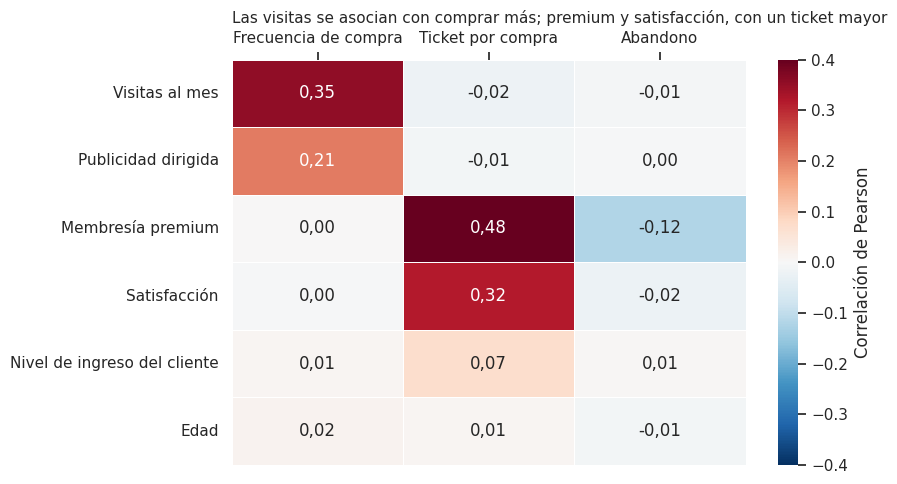

In [25]:
# Mapa de factores: qué se asocia con cada resultado de negocio
etiquetas = {
    'visitas_mes': 'Visitas al mes',
    'gasto_publicidad_dirigida': 'Publicidad dirigida',
    'miembro_premium': 'Membresía premium',
    'satisfaccion': 'Satisfacción',
    'nivel_ingreso': 'Nivel de ingreso del cliente',
    'edad': 'Edad',
}
mapa = matriz_impulsores.rename(index=etiquetas)
anotaciones = mapa.round(2).apply(lambda col: col.map(lambda v: coma(v + 0.0)))  # sin "-0,00"

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(mapa, annot=anotaciones, fmt='', cmap='RdBu_r', center=0, vmin=-0.4, vmax=0.4,
            linewidths=0.5, cbar_kws={'label': 'Correlación de Pearson'}, ax=ax)
ax.set_title('Las visitas se asocian con comprar más; premium y satisfacción, con un ticket mayor',
             fontsize=11, loc='left')
ax.set_ylabel('')
ax.xaxis.tick_top()
plt.tight_layout()
plt.show()

**Mensaje principal.** El ingreso de un cliente es, en la práctica, **cuántas veces compra × cuánto vale cada compra**, y cada una de esas dos palancas se asocia con factores distintos:

| Palanca | Factores asociados | Factores sin relación |
|---|---|---|
| **Frecuencia de compra** | Visitas al mes (0,35) y publicidad dirigida (0,21, entrelazada con las visitas) | Premium, satisfacción, edad, nivel de ingreso |
| **Ticket por compra** | Membresía premium (0,48; +25% por compra) y satisfacción (0,32) | Visitas, publicidad |
| **Retención** | Membresía premium (abandono de 4,4% frente a 16,8%) | Dispositivo, región, visitas, compras, ingreso |

### 5.2 Hallazgo 1: casi un tercio de los clientes no compra, y sin compras no hay ingreso

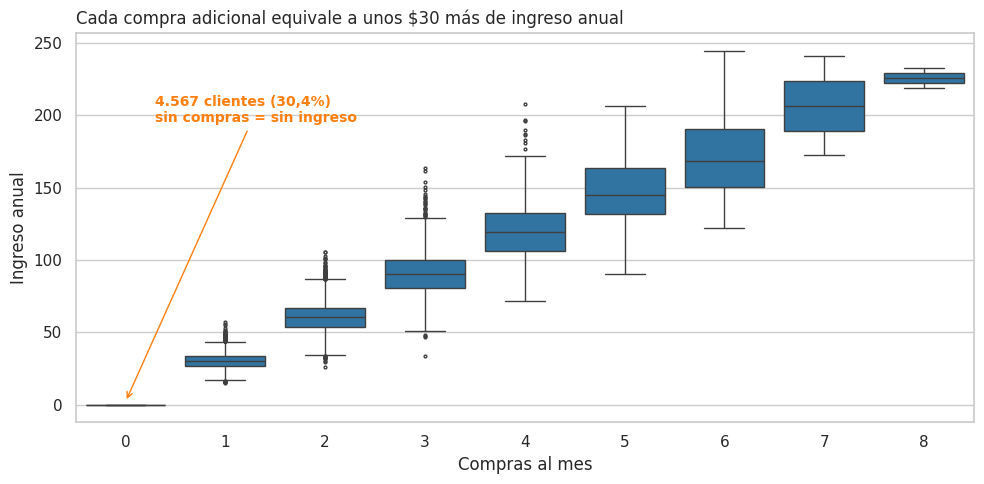

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x='compras_mes', y='ingreso_anual', color=AZUL, fliersize=2, ax=ax)

n_cero = int((df['compras_mes'] == 0).sum())
ax.annotate(f"{n_cero:,}".replace(',', '.') + " clientes (30,4%)\nsin compras = sin ingreso",
            xy=(0, 2), xytext=(0.3, 195), fontsize=10, color=NARANJA, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=NARANJA))
ax.set_title('Cada compra adicional equivale a unos $30 más de ingreso anual', fontsize=12, loc='left')
ax.set_xlabel('Compras al mes')
ax.set_ylabel('Ingreso anual')
plt.tight_layout()
plt.show()

- **Evidencia visual:** el ingreso sube en escalones regulares con cada compra; todos los clientes sin compras están en ingreso cero.
- **Evidencia numérica:** correlación compras–ingreso de 0,967 (Pearson y Spearman). Los 4.567 clientes sin compras (30,4%) tienen ingreso anual de exactamente 0. Entre quienes compran, el ingreso por compra es casi constante (media $30,38; desviación $5,34).
- **Interpretación (no causal):** la relación es casi **por construcción** (ingreso ≈ compras × ticket). Lo relevante no es que las compras expliquen el ingreso, sino que **uno de cada tres clientes no genera nada**.
- **No podemos afirmar:** que convertir a los clientes sin compras en compradores produzca el mismo ingreso que los compradores actuales; podrían ser clientes distintos.
- **Implicación de negocio:** el mayor margen de crecimiento está en **activar a los clientes sin compras**. Cada compra mensual adicional equivale a unos $30 de ingreso anual por cliente.

### 5.3 Hallazgo 2: las visitas se asocian con comprar más; la publicidad, solo a través de ellas

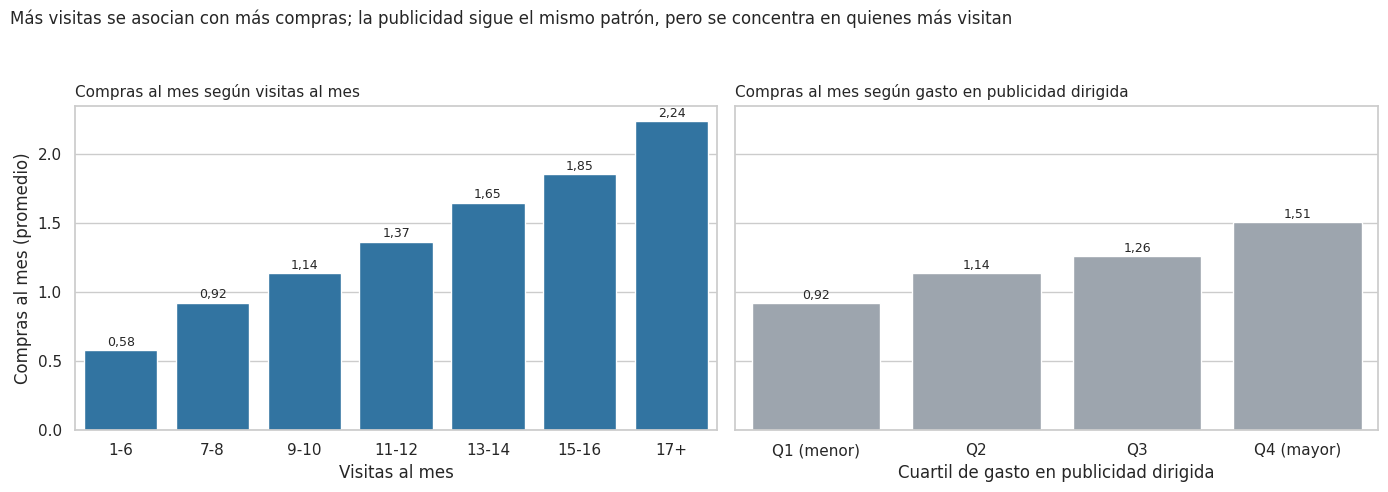

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

tramo_visitas = pd.cut(df['visitas_mes'], [0, 6, 8, 10, 12, 14, 16, 25],
                       labels=['1-6', '7-8', '9-10', '11-12', '13-14', '15-16', '17+'])
compras_visitas = df.groupby(tramo_visitas, observed=True)['compras_mes'].mean()
sns.barplot(x=compras_visitas.index, y=compras_visitas.values, color=AZUL, ax=axes[0])
axes[0].set_title('Compras al mes según visitas al mes', fontsize=11, loc='left')
axes[0].set_xlabel('Visitas al mes')
axes[0].set_ylabel('Compras al mes (promedio)')
for i, v in enumerate(compras_visitas.values):
    axes[0].text(i, v + 0.03, coma(v), ha='center', fontsize=9)

cuartil_pub = pd.qcut(df['gasto_publicidad_dirigida'], 4, labels=['Q1 (menor)', 'Q2', 'Q3', 'Q4 (mayor)'])
compras_pub = df.groupby(cuartil_pub, observed=True)['compras_mes'].mean()
sns.barplot(x=compras_pub.index, y=compras_pub.values, color=GRIS, ax=axes[1])
axes[1].set_title('Compras al mes según gasto en publicidad dirigida', fontsize=11, loc='left')
axes[1].set_xlabel('Cuartil de gasto en publicidad dirigida')
axes[1].set_ylabel('')
for i, v in enumerate(compras_pub.values):
    axes[1].text(i, v + 0.03, coma(v), ha='center', fontsize=9)

fig.suptitle('Más visitas se asocian con más compras; la publicidad sigue el mismo patrón, pero se concentra en quienes más visitan',
             fontsize=12, x=0.01, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

- **Evidencia visual:** las compras promedio suben de forma sostenida con las visitas (de 0,58 con 6 visitas o menos a 2,24 con más de 16) y, más suavemente, con el gasto en publicidad (de 0,92 en el cuartil más bajo a 1,51 en el más alto).
- **Evidencia numérica:** correlación con las compras de 0,354 para las visitas y 0,208 para la publicidad. Pero publicidad y visitas se correlacionan 0,58 entre sí, y al controlar las visitas la correlación de la publicidad con las compras cae a 0,004 (la de las visitas se mantiene en 0,293).
- **Interpretación (no causal):** los clientes que más visitan compran más. La publicidad dirigida se asocia con las compras sobre todo porque se concentra en los clientes que más visitan.
- **No podemos afirmar:** que más visitas *generen* más compras (puede que quien compra más visite más) ni que la publicidad *no funcione*: si la empresa dirige más anuncios a quienes ya visitan mucho, esta base no permite medir su efecto propio.
- **Implicación de negocio:** conviene trabajar el **engagement** (visitas) como indicador adelantado de compra, y **medir la incrementalidad de la publicidad dirigida** con una prueba controlada (por ejemplo, un grupo de control sin anuncios) antes de ajustar la inversión.

### 5.4 Hallazgo 3: los clientes premium gastan 25% más por compra y abandonan casi cuatro veces menos

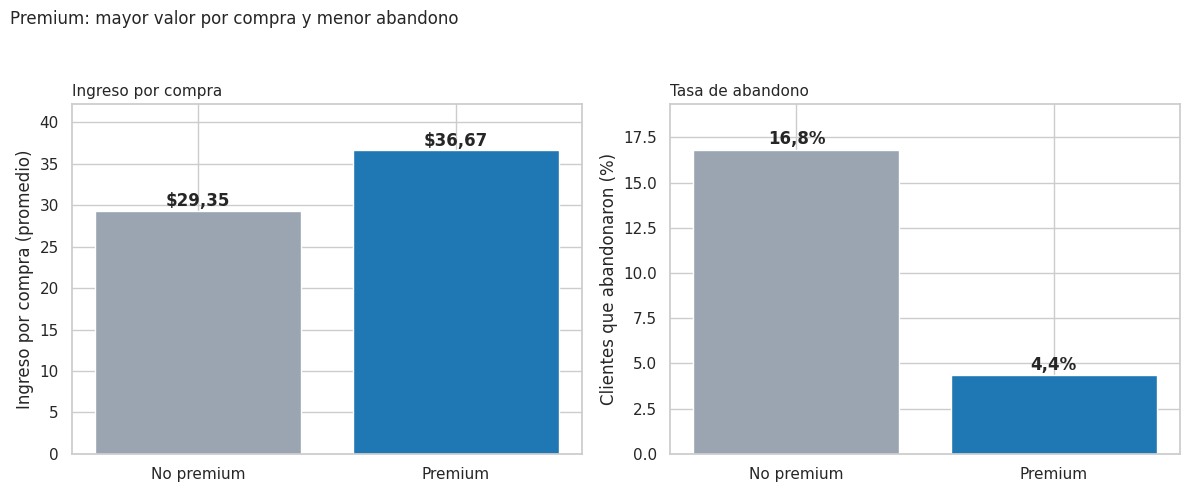

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ticket_premium = compradores.groupby('miembro_premium')['ticket'].mean()
etiquetas_premium = ['No premium', 'Premium']
axes[0].bar(etiquetas_premium, ticket_premium.values, color=[GRIS, AZUL])
axes[0].set_title('Ingreso por compra', fontsize=11, loc='left')
axes[0].set_ylabel('Ingreso por compra (promedio)')
for i, v in enumerate(ticket_premium.values):
    axes[0].text(i, v + 0.5, '$' + coma(v), ha='center', fontweight='bold')

abandono_premium = df.groupby('miembro_premium')['abandono'].mean() * 100
axes[1].bar(etiquetas_premium, abandono_premium.values, color=[GRIS, AZUL])
axes[1].set_title('Tasa de abandono', fontsize=11, loc='left')
axes[1].set_ylabel('Clientes que abandonaron (%)')
for i, v in enumerate(abandono_premium.values):
    axes[1].text(i, v + 0.3, coma(v, 1) + '%', ha='center', fontweight='bold')

axes[0].set_ylim(0, ticket_premium.max() * 1.15)
axes[1].set_ylim(0, abandono_premium.max() * 1.15)
fig.suptitle('Premium: mayor valor por compra y menor abandono', fontsize=12, x=0.01, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

- **Evidencia visual:** los clientes premium tienen un ingreso por compra más alto y una tasa de abandono mucho menor.
- **Evidencia numérica:** ingreso por compra de $36,67 frente a $29,35 (+25%); abandono de 4,4% frente a 16,8% (V de Cramér 0,120; p < 0,001). Los premium compran con la **misma frecuencia** (1,22 contra 1,21 compras al mes). Representan el 13,9% de los clientes y generan el 17,0% del ingreso. El abandono no se concentra en clientes de bajo valor: quienes abandonaron generan un ingreso medio similar al de quienes se quedaron ($36,36 frente a $36,64).
- **Interpretación (no causal):** premium se asocia con **más valor por compra** y **mejor retención**, no con más compras.
- **No podemos afirmar:** que la membresía *cause* esas diferencias. Quienes se hacen premium pueden ser clientes más comprometidos desde el inicio (autoselección). Tampoco sabemos cuándo abandonaron ni cuánto ingreso futuro se pierde.
- **Implicación de negocio:** premium es una palanca de **ticket y retención**. Vale la pena probar con un experimento (por ejemplo, ofertas de prueba de premium a una muestra aleatoria) si aumentar su penetración (hoy 13,9%) produce estos beneficios.

### 5.5 Hallazgo 4: la satisfacción se asocia con un ticket mayor, no con más compras

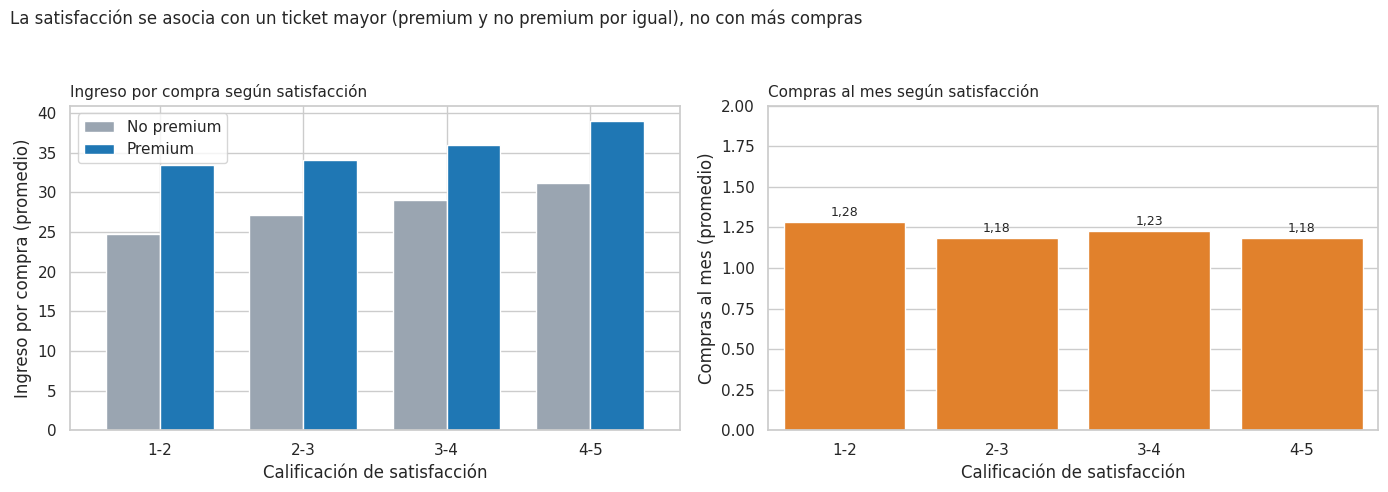

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

compradores['tramo_satisfaccion'] = pd.cut(compradores['satisfaccion'], [0.99, 2, 3, 4, 5.01],
                                           labels=['1-2', '2-3', '3-4', '4-5'], right=False)
ticket_sat = (compradores.groupby(['tramo_satisfaccion', 'miembro_premium'], observed=True)['ticket']
              .mean().unstack())
ticket_sat.columns = ['No premium', 'Premium']
ticket_sat.plot(kind='bar', color=[GRIS, AZUL], ax=axes[0], rot=0, width=0.75)
axes[0].set_title('Ingreso por compra según satisfacción', fontsize=11, loc='left')
axes[0].set_xlabel('Calificación de satisfacción')
axes[0].set_ylabel('Ingreso por compra (promedio)')
axes[0].legend(title='')

df['tramo_satisfaccion'] = pd.cut(df['satisfaccion'], [0.99, 2, 3, 4, 5.01],
                                  labels=['1-2', '2-3', '3-4', '4-5'], right=False)
compras_sat = df.groupby('tramo_satisfaccion', observed=True)['compras_mes'].mean()
sns.barplot(x=compras_sat.index, y=compras_sat.values, color=NARANJA, ax=axes[1])
axes[1].set_title('Compras al mes según satisfacción', fontsize=11, loc='left')
axes[1].set_xlabel('Calificación de satisfacción')
axes[1].set_ylabel('Compras al mes (promedio)')
axes[1].set_ylim(0, 2)
for i, v in enumerate(compras_sat.values):
    axes[1].text(i, v + 0.04, coma(v), ha='center', fontsize=9)

fig.suptitle('La satisfacción se asocia con un ticket mayor (premium y no premium por igual), no con más compras',
             fontsize=12, x=0.01, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

- **Evidencia visual:** el ingreso por compra aumenta escalonadamente con la satisfacción, en clientes premium y no premium por igual; las compras al mes se mantienen planas.
- **Evidencia numérica:** correlación satisfacción–ticket de 0,317 entre compradores y de -0,004 con la frecuencia de compra. El ticket pasa de $28,06 (satisfacción de 2 a 3) a $32,33 (4 a 5). En cada tramo de satisfacción, los clientes premium gastan entre $7 y $9 más por compra. El abandono baja de 16,9% a 13,8% entre esos mismos tramos.
- **Interpretación (no causal):** los clientes más satisfechos tienden a gastar más en cada compra, aunque no compran más veces. El efecto de la satisfacción y el de premium se suman.
- **No podemos afirmar:** que mejorar la satisfacción suba el ticket (podría ser al revés: quien gasta más recibe mejor servicio) ni que el efecto sea igual para todos los segmentos. El tramo de 1 a 2 tiene solo 90 clientes.
- **Implicación de negocio:** la satisfacción es una **palanca de valor por compra**, no de frecuencia. Sirve como indicador de seguimiento de los clientes de mayor ticket.

### 5.6 Hallazgo 5: la edad, el nivel de ingreso, el dispositivo y la región no distinguen a los clientes de mayor valor

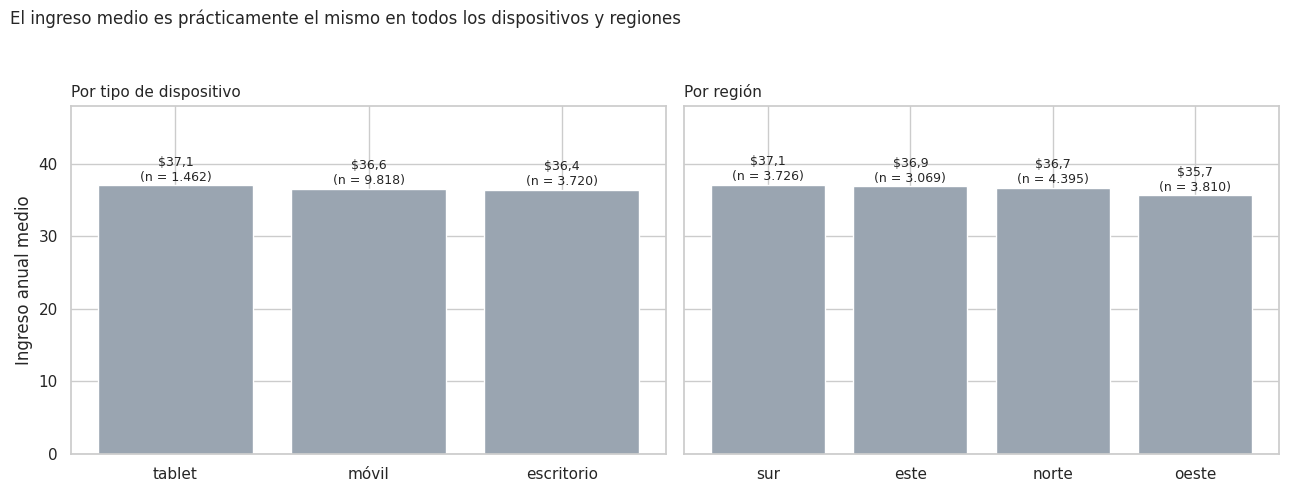

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, col, titulo in [(axes[0], 'tipo_dispositivo', 'Por tipo de dispositivo'),
                        (axes[1], 'region', 'Por región')]:
    grupo = df.groupby(col)['ingreso_anual'].agg(['mean', 'count']).sort_values('mean', ascending=False)
    ax.bar(grupo.index, grupo['mean'], color=GRIS)
    ax.set_title(titulo, fontsize=11, loc='left')
    ax.set_xlabel('')
    for i, (media, n) in enumerate(zip(grupo['mean'], grupo['count'])):
        ax.text(i, media + 0.6, '$' + coma(media, 1) + f"\n(n = {n:,})".replace(',', '.'), ha='center', fontsize=9)
    ax.set_ylim(0, 48)

axes[0].set_ylabel('Ingreso anual medio')
fig.suptitle('El ingreso medio es prácticamente el mismo en todos los dispositivos y regiones',
             fontsize=12, x=0.01, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

- **Evidencia visual:** las barras de ingreso medio son casi idénticas entre dispositivos y entre regiones.
- **Evidencia numérica:** `edad` e `ingreso_anual` correlacionan 0,017, igual que `nivel_ingreso`. Ingreso medio entre $36,42 y $37,07 según dispositivo (Kruskal-Wallis p = 0,499) y entre $35,72 y $37,10 según región (p = 0,448). El abandono no depende del dispositivo (V = 0,007) ni de la región (V = 0,015).
- **Interpretación (no causal):** estos atributos no sirven, por sí solos, para identificar a los clientes más valiosos.
- **No podemos afirmar:** que sean irrelevantes en combinación con otras variables (efectos conjuntos), ya que el análisis es de a pares.
- **Implicación de negocio:** priorizar y segmentar a los clientes por **comportamiento** (visitas, compras, membresía) más que por edad, nivel de ingreso, dispositivo o región.

---

## 6. Recomendaciones y próximos pasos

| Prioridad | Acción | Evidencia | Cómo validarlo |
|---|---|---|---|
| **1** | **Activar a los clientes sin compras** (30,4% del total) | Ingreso nulo sin compras; cada compra mensual equivale a ~$30 de ingreso anual | Campañas de primera compra con grupo de control |
| **2** | **Impulsar las visitas** y medir la incrementalidad de la publicidad dirigida | Compras de 0,58 a 2,24 según visitas; la publicidad pierde efecto al controlar las visitas (0,208 a 0,004) | Prueba con grupo sin anuncios; análisis de visitas previas a la compra |
| **3** | **Aumentar la penetración de premium** (hoy 13,9%) | Ticket +25% y abandono de 4,4% frente a 16,8% | Oferta de prueba a una muestra aleatoria de no premium |
| **4** | **Usar la satisfacción como indicador de valor por compra** | Ticket de $28,06 a $32,33 entre satisfacción de 2-3 y 4-5 | Seguimiento por segmento; pruebas de mejora de servicio |
| **5** | **Dejar de segmentar por edad, nivel de ingreso, dispositivo o región** para valor | Correlaciones de ~0,02; diferencias no significativas | Probar modelos con varias variables a la vez |

**Próximos pasos analíticos:** un modelo con varias variables a la vez (por ejemplo, regresión) para separar efectos conjuntos; datos con fechas para saber cuándo abandonan los clientes y cómo evolucionan; y la definición exacta de `ingreso_anual` (qué incluye y en qué moneda).

---

## 7. Limitaciones

- **Asociación no es causalidad.** Todos los hallazgos son correlaciones en datos observacionales; las recomendaciones proponen experimentos para validarlos.
- **El ingreso depende de las compras casi por construcción** (ingreso ≈ compras × ticket), por lo que la correlación de 0,97 no se interpreta como un descubrimiento. El "ticket por compra" es un indicador derivado (`ingreso_anual ÷ compras_mes`) y se usa como medida relativa de valor por compra, ya que no se conoce la escala exacta de ambas variables.
- **Análisis de a pares.** No se modelan efectos conjuntos entre variables; la publicidad y las visitas están correlacionadas (0,58) y no se pueden separar completamente.
- **Sin dimensión temporal.** No se sabe cuándo abandonaron los clientes ni cómo evolucionó su comportamiento.
- **Autoselección en premium.** Los clientes que contratan premium pueden diferir de los demás desde el inicio.
- **Moneda no especificada.** `ingreso_anual` no indica unidad monetaria; se muestra con "$" por simplicidad.
- **Grupos desiguales.** Premium (13,9%), tablet (9,7%) y los clientes con satisfacción de 1 a 2 (90) son grupos pequeños; sus resultados se interpretan con cautela.